# Análise de E-commerce com Python e SQL: Olist

Análise de ~100 mil pedidos reais de um marketplace brasileiro (2016 a 2018). Os dados são carregados em um banco SQLite, explorados com SQL e visualizados em Python. No final, um modelo de Machine Learning tenta prever atrasos na entrega.

**Execute as células em ordem, de cima para baixo (Run All).**

## 0. Configuração

In [1]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Garante que a pasta de imagens existe
os.makedirs('images', exist_ok=True)

## 1. Carregando os dados no banco SQLite

In [2]:
arquivos = [
    ('olist_customers_dataset.csv', 'customers'),
    ('olist_orders_dataset.csv', 'orders'),
    ('olist_order_items_dataset.csv', 'order_items'),
    ('olist_products_dataset.csv', 'products'),
    ('olist_sellers_dataset.csv', 'sellers'),
    ('olist_order_reviews_dataset.csv', 'order_reviews'),
    ('olist_order_payments_dataset.csv', 'order_payments'),
]

conexao = sqlite3.connect('olist.db')

for nome_csv, nome_tabela in arquivos:
    df = pd.read_csv(f'data/{nome_csv}')
    df.to_sql(nome_tabela, conexao, if_exists='replace', index=False)
    print(f'Tabela "{nome_tabela}" carregada com {len(df)} linhas.')

Tabela "customers" carregada com 99441 linhas.
Tabela "orders" carregada com 99441 linhas.
Tabela "order_items" carregada com 112650 linhas.
Tabela "products" carregada com 32951 linhas.
Tabela "sellers" carregada com 3095 linhas.
Tabela "order_reviews" carregada com 99224 linhas.
Tabela "order_payments" carregada com 103886 linhas.


## 2. Quais estados geram mais receita?

In [3]:
query = """
SELECT c.customer_state, ROUND(SUM(oi.price), 2) AS receita_total
FROM order_items oi
JOIN orders o ON o.order_id = oi.order_id
JOIN customers c ON c.customer_id = o.customer_id
GROUP BY c.customer_state
ORDER BY receita_total DESC
LIMIT 10
"""

receita_por_estado = pd.read_sql(query, conexao)
receita_por_estado

,customer_state,receita_total
0,SP,5202955.05
1,RJ,1824092.67
2,MG,1585308.03
3,RS,750304.02
4,PR,683083.76
5,SC,520553.34
6,BA,511349.99
7,DF,302603.94
8,GO,294591.95
9,ES,275037.31


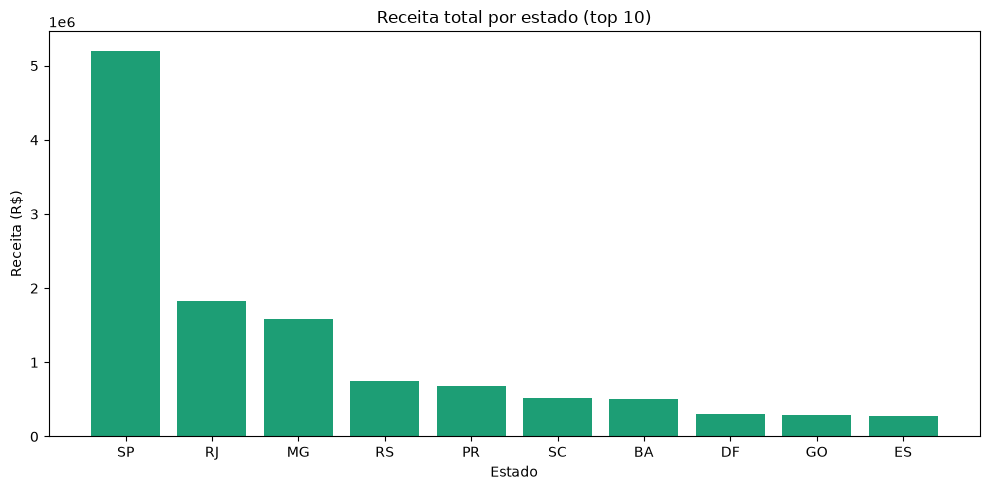

In [4]:
plt.figure(figsize=(10, 5))
plt.bar(receita_por_estado['customer_state'], receita_por_estado['receita_total'], color='#1D9E75')
plt.title('Receita total por estado (top 10)')
plt.xlabel('Estado')
plt.ylabel('Receita (R$)')
plt.tight_layout()
plt.savefig('images/receita_por_estado.png', dpi=150)
plt.show()

**Insight:** São Paulo concentra sozinho mais de R$ 5,2 milhões em receita, quase 3x o segundo colocado (Rio de Janeiro). As vendas são fortemente concentradas no Sudeste, o que é esperado pelo tamanho do mercado consumidor da região, mas evidencia dependência geográfica.

## 3. Atraso na entrega afeta a nota de avaliação?

In [5]:
query2 = """
SELECT
  CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
       THEN 'Atrasado' ELSE 'No prazo' END AS status_entrega,
  ROUND(AVG(r.review_score), 2) AS nota_media,
  COUNT(*) AS qtd_pedidos
FROM orders o
JOIN order_reviews r ON r.order_id = o.order_id
WHERE o.order_delivered_customer_date IS NOT NULL
GROUP BY status_entrega
"""

atraso_x_nota = pd.read_sql(query2, conexao)
atraso_x_nota

,status_entrega,nota_media,qtd_pedidos
0,Atrasado,2.57,7701
1,No prazo,4.29,88658


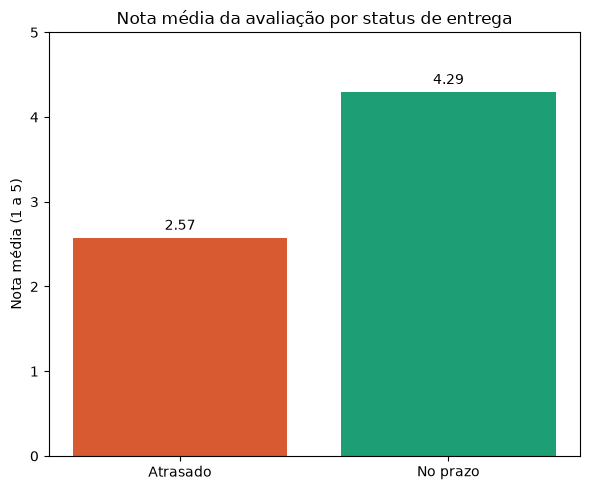

In [6]:
plt.figure(figsize=(6, 5))
cores = ['#D85A30', '#1D9E75']
plt.bar(atraso_x_nota['status_entrega'], atraso_x_nota['nota_media'], color=cores)
plt.title('Nota média da avaliação por status de entrega')
plt.ylabel('Nota média (1 a 5)')
plt.ylim(0, 5)
for i, valor in enumerate(atraso_x_nota['nota_media']):
    plt.text(i, valor + 0.1, str(valor), ha='center')
plt.tight_layout()
plt.savefig('images/nota_por_entrega.png', dpi=150)
plt.show()

**Insight:** Atraso na entrega tem impacto direto na satisfação do cliente: a nota média cai de 4,29 (no prazo) para 2,57 (atrasado). Com 7.701 pedidos atrasados na amostra, a diferença não é um caso isolado. Isso sugere que previsibilidade de entrega pode ser uma alavanca forte de retenção.

## 4. Quais categorias de produto mais vendem?

In [7]:
query3 = """
SELECT p.product_category_name, COUNT(*) AS qtd_vendida
FROM order_items oi
JOIN products p ON p.product_id = oi.product_id
GROUP BY p.product_category_name
ORDER BY qtd_vendida DESC
LIMIT 10
"""

categorias_top = pd.read_sql(query3, conexao)
categorias_top

,product_category_name,qtd_vendida
0,cama_mesa_banho,11115
1,beleza_saude,9670
2,esporte_lazer,8641
3,moveis_decoracao,8334
4,informatica_acessorios,7827
5,utilidades_domesticas,6964
6,relogios_presentes,5991
7,telefonia,4545
8,ferramentas_jardim,4347
9,automotivo,4235


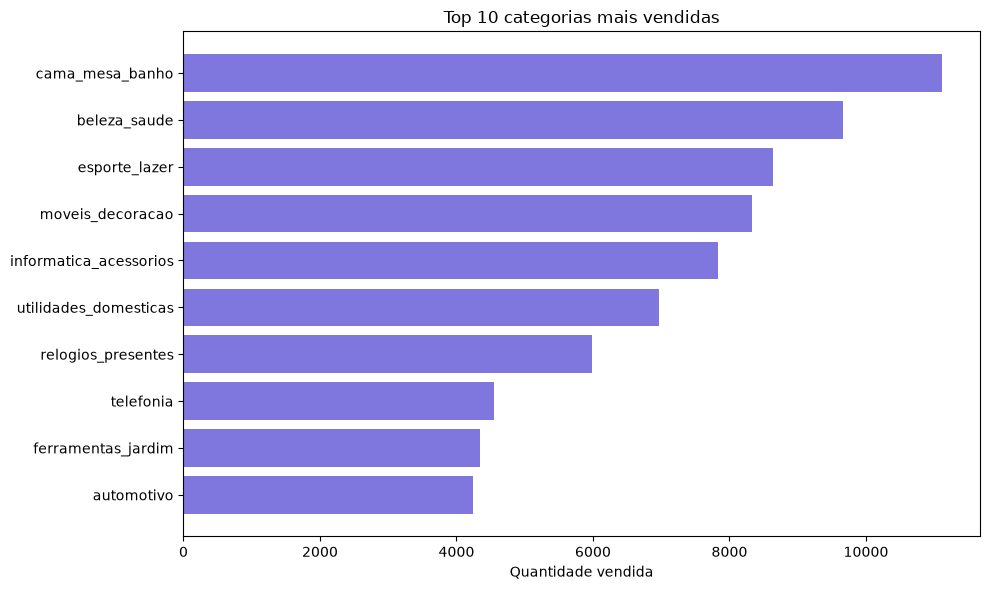

In [8]:
plt.figure(figsize=(10, 6))
plt.barh(categorias_top['product_category_name'][::-1], categorias_top['qtd_vendida'][::-1], color='#7F77DD')
plt.title('Top 10 categorias mais vendidas')
plt.xlabel('Quantidade vendida')
plt.tight_layout()
plt.savefig('images/top_categorias.png', dpi=150)
plt.show()

**Insight:** `cama_mesa_banho` lidera em volume, seguida de `beleza_saude` e `esporte_lazer`. Categorias de consumo recorrente e ticket mais baixo dominam a quantidade de itens vendidos.

## 5. Machine Learning: prevendo atraso na entrega

In [9]:
query_ml = """
SELECT
  oi.price,
  oi.freight_value,
  julianday(o.order_estimated_delivery_date) - julianday(o.order_purchase_timestamp) AS dias_estimados_entrega,
  CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 ELSE 0 END AS atrasado
FROM orders o
JOIN order_items oi ON oi.order_id = o.order_id
WHERE o.order_delivered_customer_date IS NOT NULL
"""

dados_ml = pd.read_sql(query_ml, conexao)
dados_ml.head()

,price,freight_value,dias_estimados_entrega,atrasado
0,29.99,8.72,15.544062,0
1,118.70,22.76,19.137766,0
2,159.90,19.22,26.639711,0
3,45.00,27.20,26.188819,0
4,19.90,8.72,12.112049,0


In [10]:
from sklearn.model_selection import train_test_split

dados_ml = dados_ml.dropna()

X = dados_ml[['price', 'freight_value', 'dias_estimados_entrega']]
y = dados_ml['atrasado']

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Linhas de treino: {len(X_treino)}')
print(f'Linhas de teste: {len(X_teste)}')

Linhas de treino: 88156
Linhas de teste: 22040


### Modelo 1: Regressão Logística padrão

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

modelo_base = LogisticRegression()
modelo_base.fit(X_treino, y_treino)
previsoes_base = modelo_base.predict(X_teste)

print(f'Acurácia: {accuracy_score(y_teste, previsoes_base):.2%}')
print()
print(classification_report(y_teste, previsoes_base))

Acurácia: 91.88%

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     20254
           1       0.00      0.00      0.00      1786

    accuracy                           0.92     22040
   macro avg       0.46      0.50      0.48     22040
weighted avg       0.84      0.92      0.88     22040



A acurácia de ~92% é enganosa: apenas cerca de 8% dos pedidos atrasam, e o modelo simplesmente nunca prevê atraso (recall de 0,00 para a classe "atrasado"). Esse é o problema de **classes desbalanceadas**.

### Modelo 2: Regressão Logística com classes balanceadas

In [12]:
modelo = LogisticRegression(class_weight='balanced')
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)

print(f'Acurácia: {accuracy_score(y_teste, previsoes):.2%}')
print()
print(classification_report(y_teste, previsoes))

Acurácia: 57.27%

              precision    recall  f1-score   support

           0       0.94      0.57      0.71     20254
           1       0.10      0.56      0.17      1786

    accuracy                           0.57     22040
   macro avg       0.52      0.56      0.44     22040
weighted avg       0.87      0.57      0.67     22040



**Conclusão:** ao balancear os pesos das classes, o modelo passa a identificar 56% dos atrasos reais (recall 0,56), ao custo de mais falsos alarmes (precision 0,10) e acurácia geral menor (~57%). É o trade-off clássico entre precision e recall. Com apenas 3 variáveis, o poder preditivo é limitado.

**Próximos passos:** adicionar categoria e peso do produto, mês da compra e se cliente e vendedor estão no mesmo estado; testar Random Forest; ajustar o limiar de decisão.